# 03 · Economic impact and Hurricane Melissa

Here I join the meteorology to assessed damage and loss figures from the Planning Institute of Jamaica (PIOJ), ECLAC and the World Bank (see `data/raw/jamaica_storm_impacts.csv` for sources). There are only 11 assessed events, so this section is descriptive. I'm not fitting a model to 11 points.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jhurricane import config, plotting as P

P.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

storms = pd.read_csv(config.DATA_PROCESSED / "storms.csv", parse_dates=["closest_datetime"])
seasons = pd.read_csv(config.DATA_PROCESSED / "seasons.csv")
points = pd.read_csv(config.DATA_PROCESSED / "track_points.csv", parse_dates=["datetime"])
impacts = pd.read_csv(config.DATA_PROCESSED / "impacts.csv")
near = storms[storms["is_near"]].copy()

In [2]:
imp = impacts.merge(storms[["storm_id", "max_wind_within_100nm_kt", "wind_at_closest_kt", "closest_distance_nm",
                             "approach_from", "jamaica_landfall", "rapid_intensification", "forward_speed_kt",
                             "hours_within_100nm", "category_near_jamaica"]], on="storm_id")
imp["label"] = imp["storm_name"].str.title() + " " + imp["year"].astype(str)
imp[["label", "damage_loss_usd_m", "damage_loss_pct_gdp", "deaths_jamaica", "max_wind_within_100nm_kt",
     "wind_at_closest_kt", "closest_distance_nm", "approach_from", "forward_speed_kt", "hours_within_100nm"]]

,label,damage_loss_usd_m,damage_loss_pct_gdp,deaths_jamaica,max_wind_within_100nm_kt,wind_at_closest_kt,closest_distance_nm,approach_from,forward_speed_kt,hours_within_100nm
0,Gilbert 1988,1000.0,65.0,45.0,117.0,110.0,0.0,E,14.4,22
1,Michelle 2001,53.6,0.8,NaN,NaN,120.0,271.4,W,9.7,0
2,Ivan 2004,580.0,8.0,17.0,145.0,130.0,19.1,SE,9.9,36
3,Dennis 2005,96.8,1.2,NaN,120.0,100.0,25.1,SE,13.8,19
4,Wilma 2005,56.0,0.7,NaN,33.0,25.0,38.4,SW,2.9,35
5,Dean 2007,329.0,3.4,NaN,130.0,125.0,20.3,E,17.9,17
6,Gustav 2008,214.0,2.1,NaN,73.0,60.0,0.0,E,6.7,50
7,Nicole 2010,239.6,1.9,NaN,NaN,40.0,258.8,NW,13.3,0
8,Sandy 2012,107.0,0.8,NaN,96.0,75.0,0.0,S,12.0,20
9,Beryl 2024,363.0,1.9,4.0,125.0,117.0,13.9,E,15.5,20


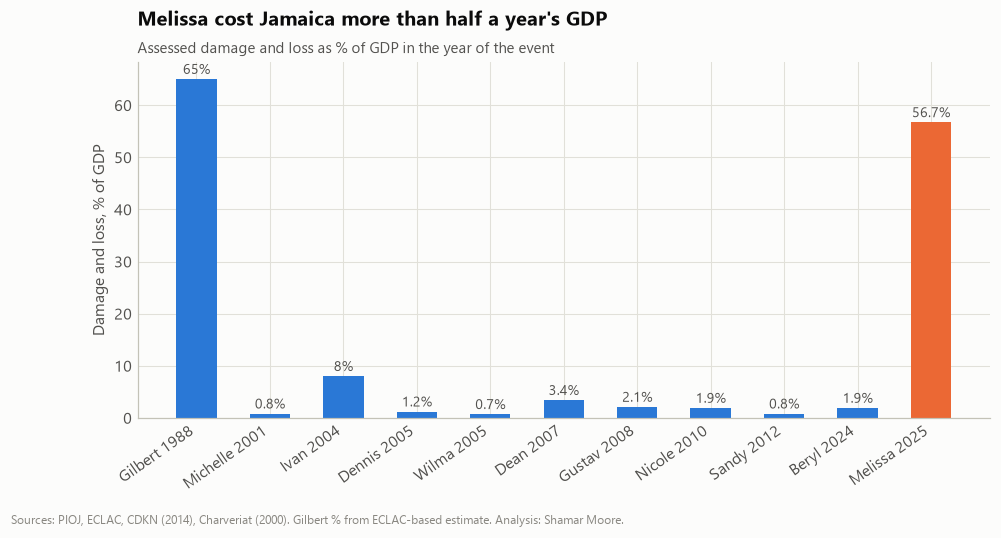

Melissa: US$12.2bn vs US$2.04bn for all nine assessed storms 2001-2024 combined (6x)


In [3]:
d = imp.sort_values("year")
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [P.ORANGE if n == "MELISSA" else P.BLUE for n in d["storm_name"]]
bars = ax.bar(d["label"], d["damage_loss_pct_gdp"], color=colors, width=0.55)
for b, v in zip(bars, d["damage_loss_pct_gdp"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:g}%", ha="center", fontsize=9, color=P.INK_2)
ax.set_ylabel("Damage and loss, % of GDP")
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_title("Melissa cost Jamaica more than half a year's GDP")
P.subtitle(ax, "Assessed damage and loss as % of GDP in the year of the event")
P.source_note(fig, "Sources: PIOJ, ECLAC, CDKN (2014), Charveriat (2000). Gilbert % from ECLAC-based estimate. Analysis: Shamar Moore.", y=-0.1)
fig.savefig(config.FIGURES / "03_damage_pct_gdp.png")
plt.show()

since_2001 = imp[(imp["year"] >= 2001) & (imp["year"] < 2025)]["damage_loss_usd_m"].sum()
mel = imp.loc[imp["storm_name"] == "MELISSA", "damage_loss_usd_m"].iat[0]
print(f"Melissa: US${mel/1000:.1f}bn vs US${since_2001/1000:.2f}bn for all nine assessed storms 2001-2024 combined "
      f"({mel/since_2001:.0f}x)")

In [4]:
from scipy.stats import spearmanr
x = imp[imp["storm_name"] != "MELISSA"]
rho_w, p_w = spearmanr(x["wind_at_closest_kt"], x["damage_loss_pct_gdp"])
rho_d, p_d = spearmanr(x["closest_distance_nm"], x["damage_loss_pct_gdp"])
print(f"Excluding Melissa (n={len(x)}): Spearman rho, wind at closest approach vs % GDP = {rho_w:.2f} (p={p_w:.2f})")
print(f"                              closest distance vs % GDP               = {rho_d:.2f} (p={p_d:.2f})")

Excluding Melissa (n=10): Spearman rho, wind at closest approach vs % GDP = 0.50 (p=0.14)
                              closest distance vs % GDP               = -0.47 (p=0.17)


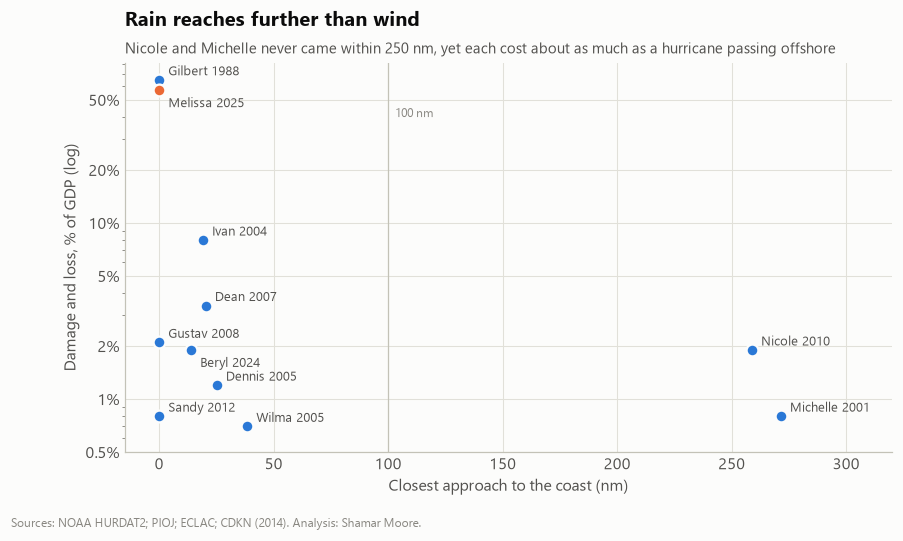

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for _, r in imp.iterrows():
    c = P.ORANGE if r["storm_name"] == "MELISSA" else P.BLUE
    ax.scatter(r["closest_distance_nm"], r["damage_loss_pct_gdp"], s=60, color=c, edgecolor=P.SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(r["label"], (r["closest_distance_nm"], r["damage_loss_pct_gdp"]),
                xytext=(6, -11) if r["storm_name"] in ("MELISSA", "BERYL") else (6, 3),
                textcoords="offset points", fontsize=8.5, color=P.INK_2)
ax.axvline(100, color=P.AXIS, lw=0.8, zorder=1)
ax.text(103, 40, "100 nm", fontsize=8, color=P.MUTED)
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50], ["0.5%", "1%", "2%", "5%", "10%", "20%", "50%"])
ax.set_xlim(-15, 320)
ax.set_xlabel("Closest approach to the coast (nm)")
ax.set_ylabel("Damage and loss, % of GDP (log)")
ax.set_title("Rain reaches further than wind")
P.subtitle(ax, "Nicole and Michelle never came within 250 nm, yet each cost about as much as a hurricane passing offshore")
P.source_note(fig, "Sources: NOAA HURDAT2; PIOJ; ECLAC; CDKN (2014). Analysis: Shamar Moore.")
fig.savefig(config.FIGURES / "03_wind_vs_damage.png")
plt.show()

## Melissa in context

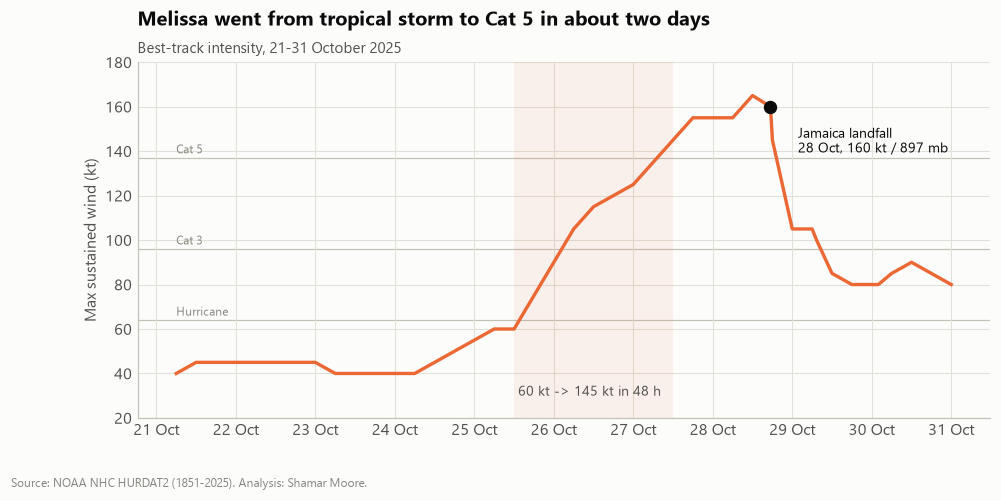

In [6]:
fixes_m = points[points["storm_id"] == near.loc[near["storm_name"] == "MELISSA", "storm_id"].iat[0]].copy()
fixes_m = fixes_m[fixes_m["datetime"] <= "2025-10-31"]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(fixes_m["datetime"], fixes_m["wind_kt"], color=P.ORANGE, lw=2.2)
for thr, lab in [(64, "Hurricane"), (96, "Cat 3"), (137, "Cat 5")]:
    ax.axhline(thr, color=P.AXIS, lw=0.8, zorder=0)
    ax.text(fixes_m["datetime"].iat[0], thr + 2, lab, fontsize=8, color=P.MUTED)
ri = fixes_m[(fixes_m["datetime"] >= "2025-10-25 12:00") & (fixes_m["datetime"] <= "2025-10-27 12:00")]
ax.axvspan(ri["datetime"].min(), ri["datetime"].max(), color=P.ORANGE, alpha=0.08, lw=0)
ax.text(ri["datetime"].min(), 30, " 60 kt -> 145 kt in 48 h", fontsize=9, color=P.INK_2)
lf = fixes_m[fixes_m["record_id"] == "L"].iloc[0]
ax.scatter([lf["datetime"]], [lf["wind_kt"]], s=60, color=P.INK, zorder=4)
ax.annotate("Jamaica landfall\n28 Oct, 160 kt / 897 mb", (lf["datetime"], lf["wind_kt"]), xytext=(18, -30),
            textcoords="offset points", fontsize=9, color=P.INK)
ax.set_ylabel("Max sustained wind (kt)")
ax.set_ylim(20, 180)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Melissa went from tropical storm to Cat 5 in about two days")
P.subtitle(ax, "Best-track intensity, 21-31 October 2025")
P.source_note(fig)
fig.savefig(config.FIGURES / "03_melissa_intensity.png")
plt.show()

In [7]:
cols = ["storm_label", "max_wind_within_100nm_kt", "min_pressure_within_100nm_mb", "forward_speed_kt",
        "hours_within_100nm", "max_24h_intensification_kt", "approach_from"]
ref = near.sort_values("max_wind_within_100nm_kt", ascending=False).head(6)[cols]
ref["rank_by_wind"] = range(1, len(ref) + 1)
ref

,storm_label,max_wind_within_100nm_kt,min_pressure_within_100nm_mb,forward_speed_kt,hours_within_100nm,max_24h_intensification_kt,approach_from,rank_by_wind
897,Melissa (2025),165.0,892.0,8.2,83,45.0,SW,1
755,Ivan (2004),145.0,910.0,9.9,36,20.0,SE,2
760,Emily (2005),140.0,929.0,15.9,11,40.0,SE,3
619,Allen (1980),132.0,948.0,21.4,14,45.0,E,4
775,Dean (2007),130.0,925.0,17.9,17,65.0,E,5
886,Beryl (2024),125.0,951.0,15.5,20,45.0,E,6


In [8]:
slow = near.loc[near["is_hurricane_near"], "forward_speed_kt"]
m = near.loc[near["storm_name"].eq("MELISSA") & near["year"].eq(2025)].iloc[0]
print(f"Melissa: {m['hours_within_100nm']} hours within 100 nm, forward speed {m['forward_speed_kt']} kt at closest approach")
print(f"Median hurricane near Jamaica: {near.loc[near['is_hurricane_near'], 'hours_within_100nm'].median():.0f} hours within 100 nm, "
      f"{slow.median():.1f} kt forward speed")
print(f"Melissa's time within 100 nm ranks #{(near['hours_within_100nm'] >= m['hours_within_100nm']).sum()} of {len(near)} storms")

Melissa: 83 hours within 100 nm, forward speed 8.2 kt at closest approach
Median hurricane near Jamaica: 20 hours within 100 nm, 12.4 kt forward speed
Melissa's time within 100 nm ranks #2 of 104 storms


### Takeaways

* **Melissa is in a class of its own:** the strongest landfall in Jamaica's record (160 kt, 897 mb), a ~US$12bn damage and loss bill (56.7% of 2024 GDP per PIOJ/ECLAC), and about 6× the combined assessed cost of all nine assessed storms from 2001 to 2024.
* It combined the three worst traits at once: **extreme peak intensity**, **rapid intensification** right before landfall (shrinking warning lead time), and **slow motion**, which meant days of rain and wind over the island.
* **Below the catastrophic tier, wind and distance are weak predictors of cost** (Spearman ρ ≈ 0.5, not significant with n = 10). Nicole (2010) and Michelle (2001) never came within 250 nm, yet their rain caused losses comparable to Beryl and Dennis passing just offshore. Flood and landslide risk needs its own planning track, separate from wind.